# Customer Count Per Country

This notebook connects to the Northwind SQL Server database,
retrieves customer data, and visualises the number of customers
in each country using Pandas and Matplotlib.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, URL, text

In [6]:
connection_url = URL.create(
    "mssql+pyodbc",
    username="sa",
    password="SalmaSQL2026Aa#2026",
    host="localhost",
    port=1433,
    database="Northwind",
    query={
        "driver": "ODBC Driver 18 for SQL Server",
        "TrustServerCertificate": "yes"
    }
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print(connection.execute(text("SELECT 1")).scalar())

print("Connected to Northwind successfully!")

1
Connected to Northwind successfully!


## Customer Count Per Country

This analysis shows how many customers are registered in each country.

In [7]:
query = """
SELECT Country, COUNT(*) AS CustomerCount
FROM Customers
GROUP BY Country
ORDER BY CustomerCount DESC;
"""

df = pd.read_sql(query, engine)

df.head()

,Country,CustomerCount
0,USA,13
1,France,11
2,Germany,11
3,Brazil,9
4,UK,7


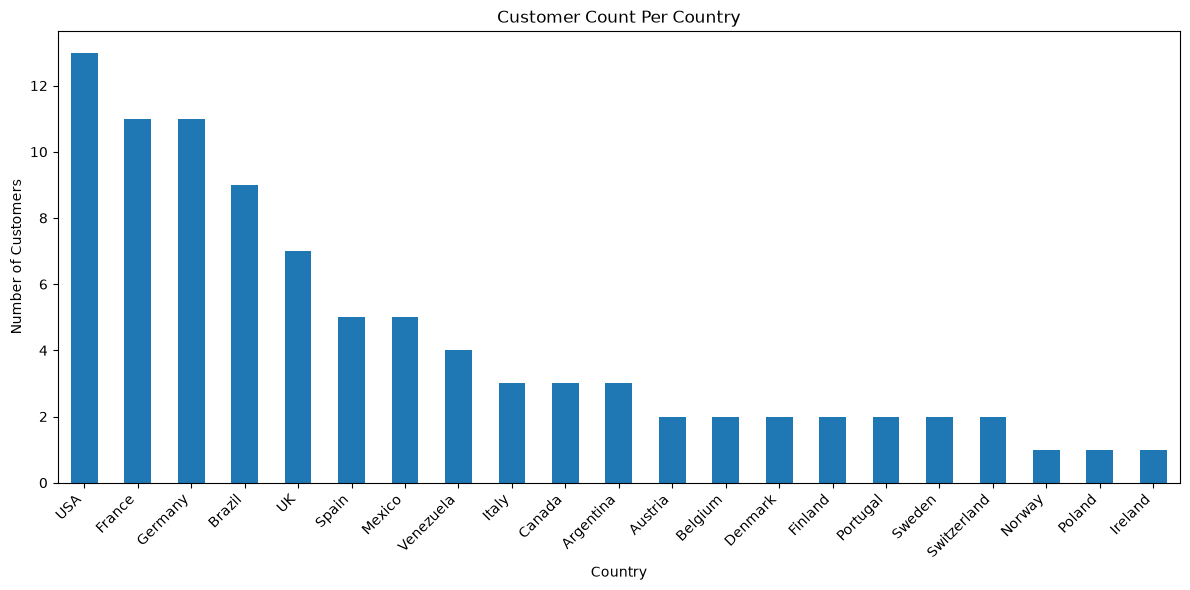

In [8]:
df.plot(
    x="Country",
    y="CustomerCount",
    kind="bar",
    figsize=(12, 6),
    legend=False
)

plt.title("Customer Count Per Country")
plt.xlabel("Country")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()